# Module2:End Project

**Preprocessing**

In [ ]:
#Importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [ ]:
import pandas as pd

# Read the dataset (corrected filename to include the missing space)
data_BM = pd.read_csv("ABC Company.xlsx - Sheet1.csv")
# Display the first five rows
print(data_BM.head())
#Display dataset information
print(data_BM.info())
# Check missing values
print(data_BM.isnull().sum())

            Name            Team  Number Position  Age  Height  Weight  \
0  Avery Bradley  Boston Celtics       0       PG   25  06-Feb     180   
1    Jae Crowder  Boston Celtics      99       SF   25  06-Jun     235   
2   John Holland  Boston Celtics      30       SG   27  06-May     205   
3    R.J. Hunter  Boston Celtics      28       SG   22  06-May     185   
4  Jonas Jerebko  Boston Celtics       8       PF   29  06-Oct     231   

             College     Salary  
0              Texas  7730337.0  
1          Marquette  6796117.0  
2  Boston University        NaN  
3      Georgia State  1148640.0  
4                NaN  5000000.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 458 entries, 0 to 457
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      458 non-null    object 
 1   Team      458 non-null    object 
 2   Number    458 non-null    int64  
 3   Position  458 non-null    object 
 4   Age     

**Correct the height column**

In [ ]:
# Replace height with random integers between 150 and 180
data_BM["Height"]=np.random.randint(150,181,size=len(data_BM))
# Display the updated height column
print(data_BM[["Height"]].head())
# Check the minimum and maximum height
print(data_BM["Height"].min())
print(data_BM["Height"].max())

   Height
0     172
1     173
2     157
3     177
4     172
150
180


**Distribution of employees across each team**

In [ ]:
# Count employees in each team
team_count=data_BM["Team"].value_counts()
# Calculate Percentage
team_percentage=(team_count/len(data_BM))*100
# combine the results
team_distribution=pd.DataFrame({"Employee count":team_count,"percentage":team_percentage})
print(team_distribution)

                        Employee count  percentage
Team                                              
New Orleans Pelicans                19    4.148472
Memphis Grizzlies                   18    3.930131
Utah Jazz                           16    3.493450
Milwaukee Bucks                     16    3.493450
New York Knicks                     16    3.493450
Boston Celtics                      15    3.275109
Los Angeles Clippers                15    3.275109
Los Angeles Lakers                  15    3.275109
Phoenix Suns                        15    3.275109
Sacramento Kings                    15    3.275109
Brooklyn Nets                       15    3.275109
Philadelphia 76ers                  15    3.275109
Toronto Raptors                     15    3.275109
Golden State Warriors               15    3.275109
Indiana Pacers                      15    3.275109
Detroit Pistons                     15    3.275109
Cleveland Cavaliers                 15    3.275109
Chicago Bulls                  

**Visualization: Employee distribution by team**

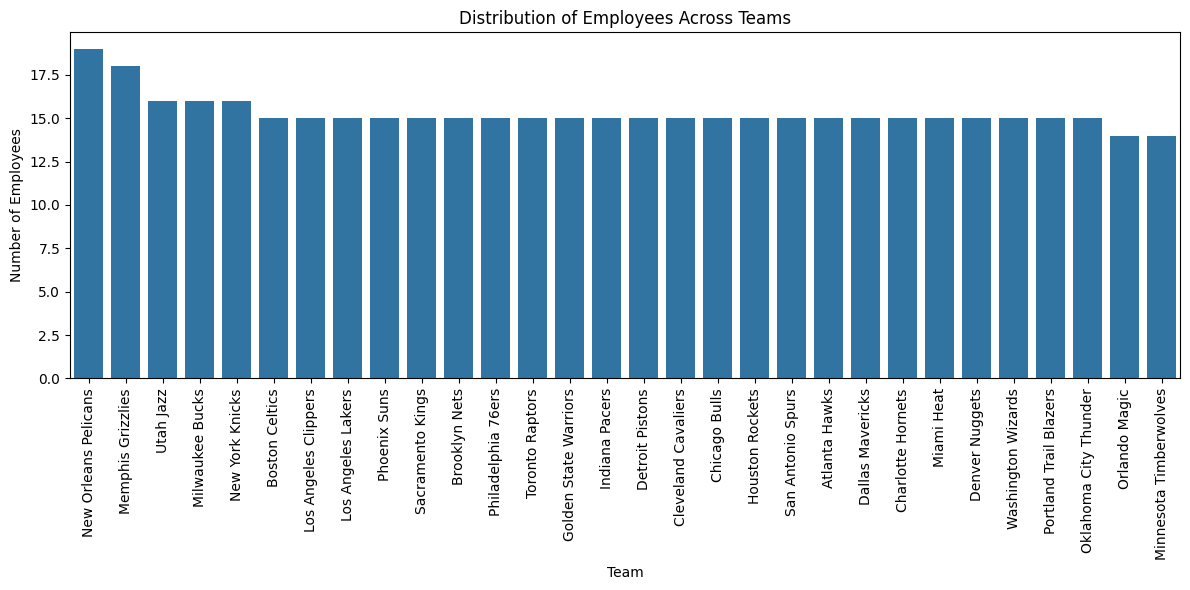

In [ ]:
plt.figure(figsize=(12,6))
sns.barplot(x=team_count.index,y=team_count.values)
plt.title("Distribution of Employees Across Teams")
plt.xlabel("Team")
plt.ylabel("Number of Employees")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Visualization: Percentage split**

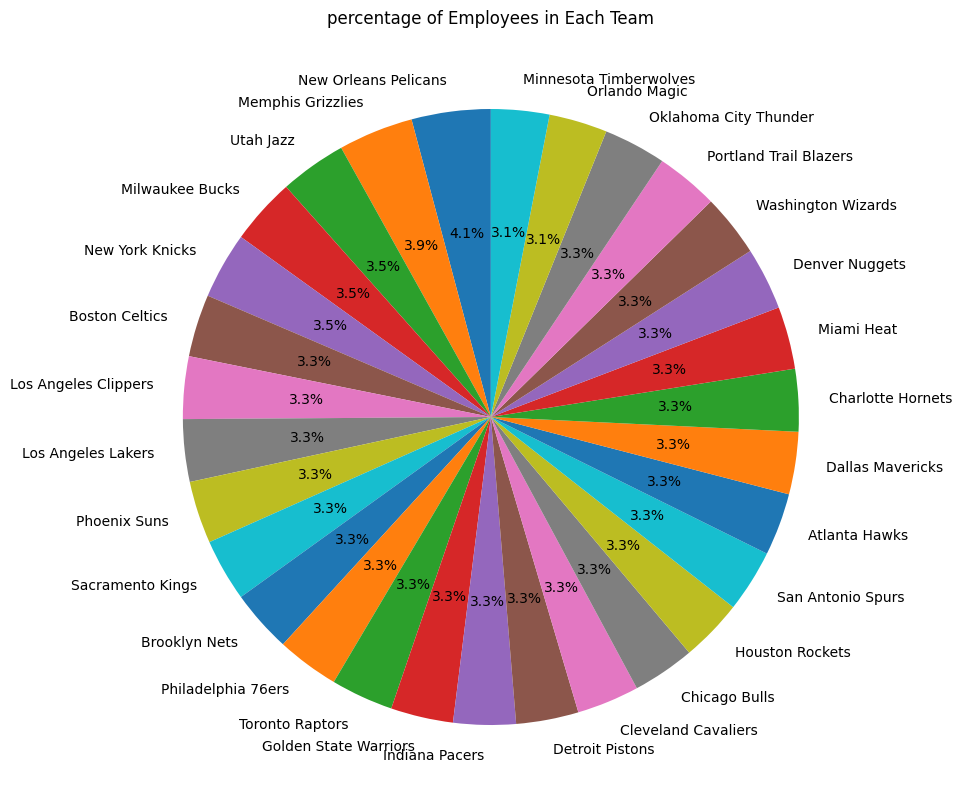

In [ ]:
plt.figure(figsize=(10,10))
plt.pie(team_count.values,labels=team_count.index,autopct="%1.1f%%",startangle=90)
plt.title("percentage of Employees in Each Team")
plt.show()

**Segregate employess based on their positions**

In [ ]:
# Count employees in each position
position_count = data_BM["Position"].value_counts()
print(position_count)

Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64


**Visualization: Employee by position**

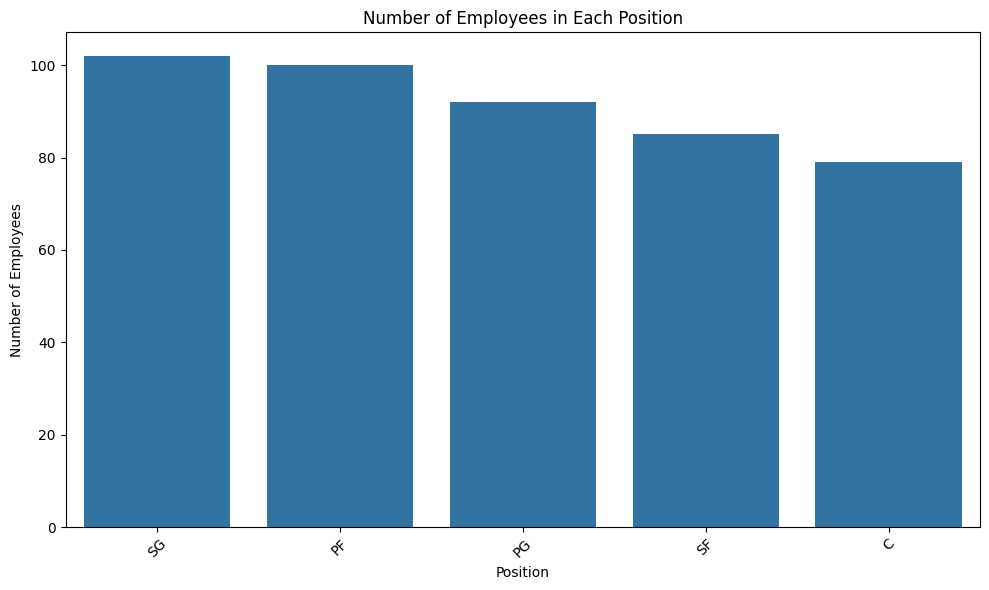

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(data=data_BM, x="Position", order=data_BM["Position"].value_counts().index)
plt.title("Number of Employees in Each Position")
plt.xlabel("Position")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Identify the predominanat age group**

In [7]:
import pandas as pd
import numpy as np

# Reload dataset if not in memory
try:
    data_BM
except NameError:
    data_BM = pd.read_csv("ABC Company.xlsx - Sheet1.csv")
    data_BM["Height"] = np.random.randint(150, 181, size=len(data_BM))

# Define age groups
bins= [0,20,30,40,50,60]
labels=["Below 20","20-29","30-39","40-49","50-60"]
# Create age group
data_BM["Age Group"]=pd.cut(data_BM["Age"],bins=bins,labels=labels,right=False)
# Count employees in each age group
age_group_count=data_BM["Age Group"].value_counts().sort_index()
print(age_group_count)
# Identify the predominant age group
predominant_age_group=age_group_count.idxmax()
print("Predominant Age Group:",predominant_age_group)
print("Number Of Employees:",age_group_count.max())

Age Group
Below 20      2
20-29       334
30-39       119
40-49         3
50-60         0
Name: count, dtype: int64
Predominant Age Group: 20-29
Number Of Employees: 334


**Visualization: Age group distribution**

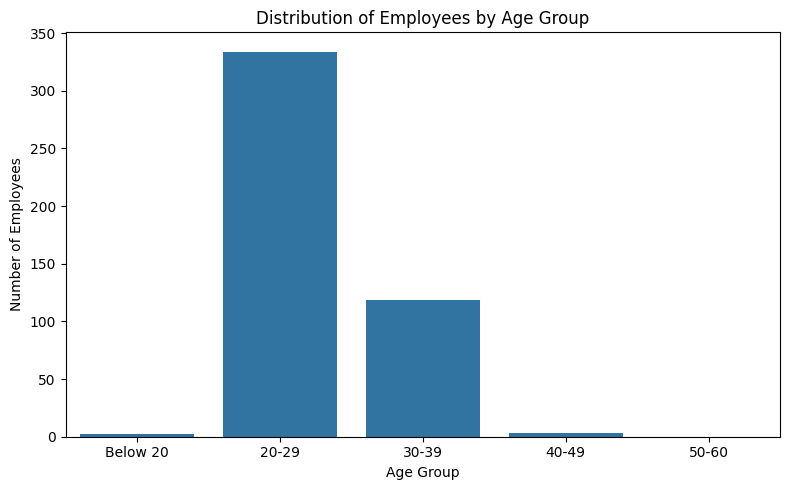

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(data=data_BM, x="Age Group", order=labels)
plt.title("Distribution of Employees by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

*Observation: Maximum number of employees are in the age group 20-29*

**Salary expenditure by team**

In [12]:
# Calculate total salary for each team
team_salary = data_BM.groupby("Team")["Salary"].sum()
print(team_salary.sort_values(ascending=False))
# Find the team with the highest salary expenditure
highest_team = team_salary.idxmax()
highest_team_salary = team_salary.max()
print("Team With Highest Salary Expenditure:", highest_team)
print("Total Salary:", highest_team_salary)

Team
Cleveland Cavaliers       106988689.0
Los Angeles Clippers       94854640.0
Oklahoma City Thunder      93765298.0
Golden State Warriors      88868997.0
Chicago Bulls              86783378.0
San Antonio Spurs          84442733.0
New Orleans Pelicans       82750774.0
Miami Heat                 82515673.0
Charlotte Hornets          78340920.0
Memphis Grizzlies          76550880.0
Washington Wizards         76328636.0
Houston Rockets            75283021.0
New York Knicks            73303898.0
Atlanta Hawks              72902950.0
Los Angeles Lakers         71770431.0
Sacramento Kings           71683666.0
Dallas Mavericks           71198732.0
Toronto Raptors            71117611.0
Milwaukee Bucks            69603517.0
Detroit Pistons            67168263.0
Indiana Pacers             66751826.0
Utah Jazz                  64007367.0
Phoenix Suns               63445135.0
Orlando Magic              60161470.0
Denver Nuggets             60121930.0
Minnesota Timberwolves     59709697.0
Boston 

**Visualization: Salary expenditure by team**

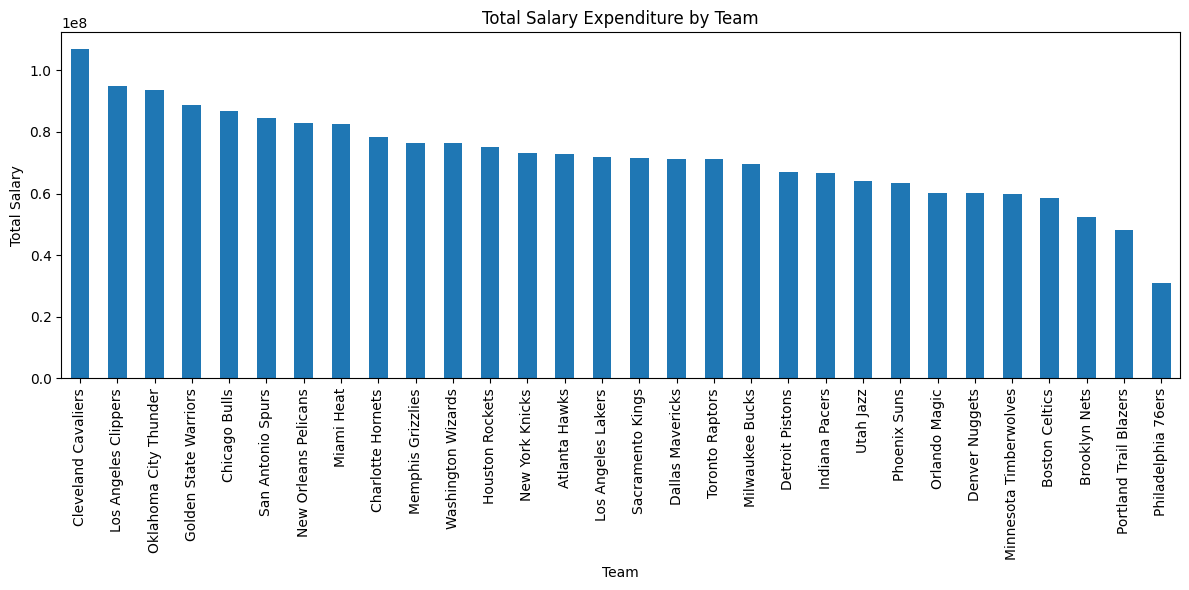

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data_BM = pd.read_csv("ABC Company.xlsx - Sheet1.csv")
team_salary = data_BM.groupby("Team")["Salary"].sum()

plt.figure(figsize=(12,6))
team_salary.sort_values(ascending=False).plot(kind="bar")
plt.title("Total Salary Expenditure by Team")
plt.xlabel("Team")
plt.ylabel("Total Salary")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

*Observation: Team Cleveland cavaliers have highest expenditure*

**Salary expenditure by position**

In [6]:
# Calculate total salary for each position
position_salary = data_BM.groupby("Position")["Salary"].sum()
print(position_salary.sort_values(ascending=False))
# Find the position with the highest salary expenditure
highest_position = position_salary.idxmax()
highest_position_salary = position_salary.max()
print("Position With Highest Salary Expenditure:", highest_position)
print("Total Salary:", highest_position_salary)

Position
C     466377332.0
PG    446848971.0
PF    442560850.0
SF    408020976.0
SG    396976258.0
Name: Salary, dtype: float64
Position With Highest Salary Expenditure: C
Total Salary: 466377332.0


**Visualization: Salary expenditure by position**

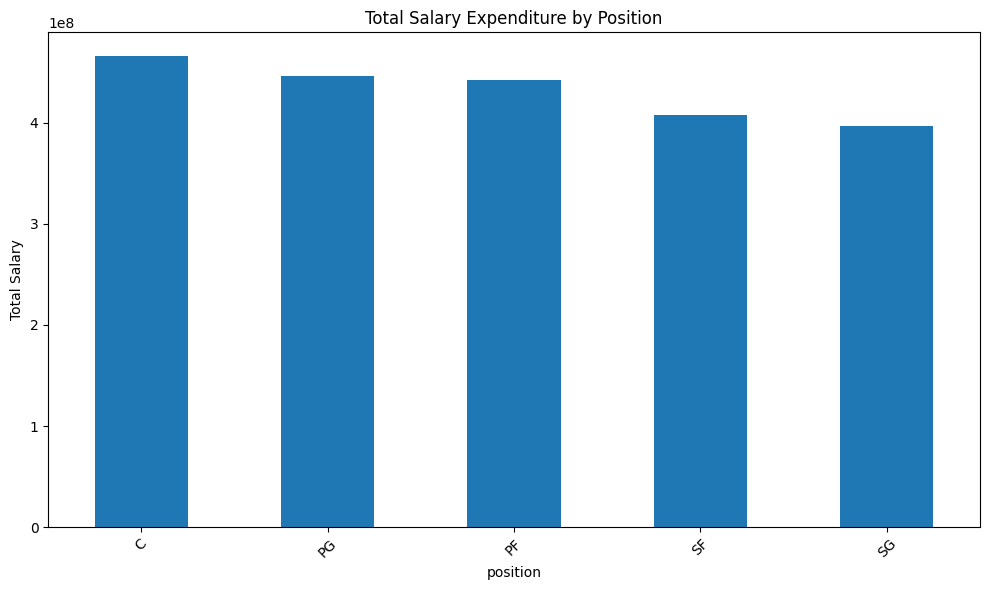

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
data_BM = pd.read_csv("ABC Company.xlsx - Sheet1.csv")
position_salary = data_BM.groupby("Position")["Salary"].sum()
plt.figure(figsize=(10,6))
position_salary.sort_values(ascending=False).plot(kind="bar")
plt.title("Total Salary Expenditure by Position")
plt.xlabel("position")
plt.ylabel("Total Salary")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

*Observation: Position c has highest salary expenditure*

**Investigate the correlation between age and salary**

In [9]:
# Calculate correlation
correlation = data_BM["Age"].corr(data_BM["Salary"])
print("correlation between Age and Salary:", correlation)

correlation between Age and Salary: 0.21400941226570971


**Visualization:Scatter plot with regression line**

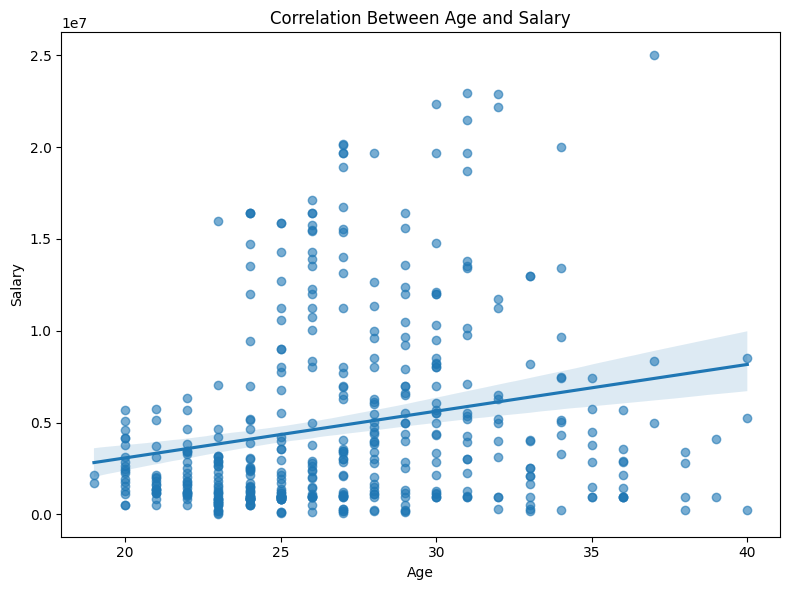

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
data_BM = pd.read_csv("ABC Company.xlsx - Sheet1.csv")
plt.figure(figsize=(8,6))
sns.regplot(data=data_BM,x="Age",y="Salary",scatter_kws={"alpha":0.6})
plt.title("Correlation Between Age and Salary")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.tight_layout()
plt.show()

*Observation: There is a weak or moderate positive correlation between Age and Salary.*